# Exercise: Generalised Linear Regression

**Course:** BERN02  
**Name:** Ran Tao  

## Poisson Regression of Bird Counts

In this exercise, I fit a Poisson regression model to bird count data collected between 1999 and 2012. Year is used as the predictor variable and bird count as the response variable.

The parameters are estimated by maximum likelihood. The log-likelihood function is implemented directly, while a general-purpose numerical optimisation function is used to obtain the parameter estimates.

Finally, the fitted model is used to generate three hypothetical samples of bird counts.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.special import gammaln

## 1. Load and inspect the data

The data contain bird counts from one site over several years. The response variable is `count`, and the predictor used in this analysis is `yr`.

In [5]:
data = pd.read_csv("bird_count.csv")

data = data.sort_values("yr").reset_index(drop=True)

print(data)

    count    yr  observerAge   lineCov
0      10  1999           27  0.991667
1       5  2000           28  0.991667
2       9  2001           29  0.991667
3      12  2002           30  0.991667
4      14  2004           58  1.000000
5       8  2005           59  0.987500
6      12  2006           60  0.987500
7       9  2007           61  0.987500
8       5  2008           62  0.987500
9       5  2009           63  0.987500
10      5  2010           64  0.987500
11      2  2011           63  1.000000
12     12  2012           64  1.000000


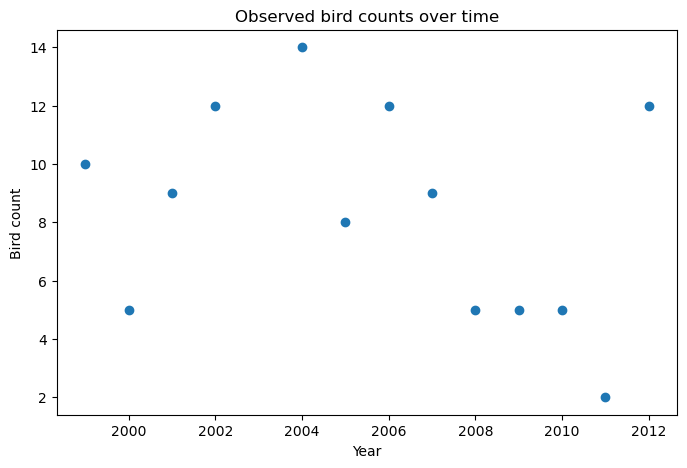

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(data["yr"], data["count"])

plt.xlabel("Year")
plt.ylabel("Bird count")
plt.title("Observed bird counts over time")

plt.show()

## 2. Poisson Regression Model

Let $Y_i$ denote the observed bird count in year $i$. We assume that:

$$
Y_i \sim \text{Poisson}(\lambda_i)
$$

where $\lambda_i$ is the expected bird count.

A log link is used to relate the expected count to the year:

$$
\log(\lambda_i) = \beta_0 + \beta_1 x_i
$$

where:

$$
x_i = \text{year}_i - 1999
$$

Therefore, the expected count can be expressed as:

$$
\lambda_i = \exp(\beta_0 + \beta_1 x_i)
$$

### Interpretation

- **Centering the year:** We center the year at 1999 to make the intercept easier to interpret and to improve numerical stability. With this parameterization, $\exp(\beta_0)$ represents the expected bird count in the year 1999.
- **Slope coefficient:** The coefficient $\beta_1$ describes the change in the log expected count for each additional year. Equivalently, $\exp(\beta_1)$ represents the **multiplicative change** in the expected bird count per year.

In [7]:
y = data["count"].to_numpy()

x = (data["yr"] - 1999).to_numpy()

print("x =", x)
print("y =", y)

x = [ 0  1  2  3  5  6  7  8  9 10 11 12 13]
y = [10  5  9 12 14  8 12  9  5  5  5  2 12]


## 3. Maximum Likelihood Estimation

For a Poisson random variable, the probability mass function is:

$$
P(Y_i = y_i) = \frac{\lambda_i^{y_i} e^{-\lambda_i}}{y_i!}
$$

Assuming that observations are independent, the log-likelihood for the complete data set is:

$$
\ell(\beta_0, \beta_1) = \sum_i \left[ y_i \log(\lambda_i) - \lambda_i - \log(y_i!) \right]
$$

where:

$$
\lambda_i = \exp(\beta_0 + \beta_1 x_i)
$$

### Implementation Note

- **Custom Implementation:** I implement this log-likelihood directly rather than using a ready-made Poisson regression or maximum likelihood estimation function.
- **Optimization:** The optimization function in SciPy performs minimization, so I minimize the **negative log-likelihood**.

In [8]:
def negative_log_likelihood(beta, x, y):
    beta0 = beta[0]
    beta1 = beta[1]

    eta = beta0 + beta1 * x
    lam = np.exp(eta)

    log_likelihood = np.sum(
        y * eta - lam - gammaln(y + 1)
    )

    return -log_likelihood

In [9]:
initial_values = np.array([np.log(np.mean(y)), 0.0])

result = minimize(
    negative_log_likelihood,
    initial_values,
    args=(x, y),
    method="BFGS"
)

beta0_hat = result.x[0]
beta1_hat = result.x[1]

print("Optimization successful:", result.success)
print("Estimated beta0:", beta0_hat)
print("Estimated beta1:", beta1_hat)

print("Expected count in 1999:", np.exp(beta0_hat))
print("Multiplicative change per year:", np.exp(beta1_hat))

Optimization successful: True
Estimated beta0: 2.3253319393276772
Estimated beta1: -0.032443179463123376
Expected count in 1999: 10.230075286572204
Multiplicative change per year: 0.9680774549493094


## 4. Parameter Estimates

The estimated model is approximately:

$$
\log(\hat{\lambda}) = 2.3253 - 0.03244(\text{year} - 1999)
$$

The estimated expected bird count in 1999 is:

$$
\exp(2.3253) \approx 10.23
$$

The estimated multiplicative change in the expected count for each additional year is:

$$
\exp(-0.03244) \approx 0.968
$$

### Interpretation

Thus, according to the fitted model, the expected bird count is multiplied by approximately **0.968** for each additional year. This corresponds to an estimated **decrease of about 3.2% per year**.

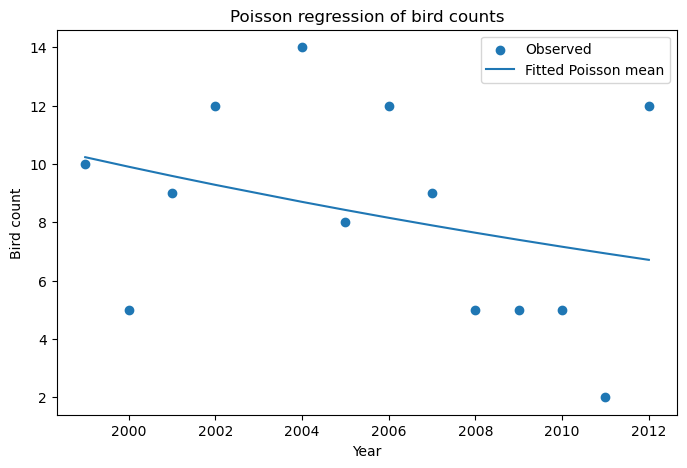

,yr,count,fitted_count
0,1999,10,10.230075
1,2000,5,9.903505
2,2001,9,9.587360
3,2002,12,9.281307
4,2004,14,8.698199
5,2005,8,8.420531
6,2006,12,8.151726
7,2007,9,7.891502
8,2008,5,7.639585
9,2009,5,7.395710


In [10]:
data["fitted_count"] = np.exp(
    beta0_hat + beta1_hat * (data["yr"] - 1999)
)

plt.figure(figsize=(8, 5))

plt.scatter(
    data["yr"],
    data["count"],
    label="Observed"
)

plt.plot(
    data["yr"],
    data["fitted_count"],
    label="Fitted Poisson mean"
)

plt.xlabel("Year")
plt.ylabel("Bird count")
plt.title("Poisson regression of bird counts")
plt.legend()

plt.show()

data[["yr", "count", "fitted_count"]]

## 5. Generate Hypothetical Observations

I now use the point estimates of the fitted parameters to generate three hypothetical samples.

For every observed year, the fitted Poisson mean is:

$$
\hat{\lambda}_i = \exp(\hat{\beta}_0 + \hat{\beta}_1 x_i)
$$

For each of the three samples, a new bird count is independently generated from:

$$
Y_i^{(s)} \sim \text{Poisson}(\hat{\lambda}_i)
$$


In [11]:
rng = np.random.default_rng(123)

years = data["yr"].to_numpy()
fitted_lambda = data["fitted_count"].to_numpy()

samples = []

for sample_id in range(1, 4):
    
    simulated_counts = rng.poisson(fitted_lambda)
    
    sample_data = pd.DataFrame({
        "year": years,
        "count": simulated_counts,
        "sample": sample_id
    })
    
    samples.append(sample_data)

simulated_data = pd.concat(samples, ignore_index=True)

simulated_data

,year,count,sample
0,1999,12,1
1,2000,11,1
2,2001,11,1
3,2002,14,1
4,2004,5,1
5,2005,5,1
6,2006,12,1
7,2007,9,1
8,2008,4,1
9,2009,9,1


In [12]:
output_file = "bird_count_simulated_samples.csv"

simulated_data.to_csv(
    output_file,
    index=False
)

print("Saved simulated samples to:", output_file)

Saved simulated samples to: bird_count_simulated_samples.csv


## 6. Conclusion

A Poisson regression model with year as the predictor was fitted to the bird count data using maximum likelihood estimation.

The log-likelihood was implemented directly, and a general-purpose numerical optimiser was used to estimate the model parameters. The fitted model suggests a decreasing expected bird count over time, with an estimated multiplicative change of approximately 0.968 per year.

Finally, the fitted parameter estimates were used to generate three hypothetical samples from the Poisson model. These simulated observations were saved in `bird_count_simulated_samples.csv`.